### IMPORTING LIBRARY

In [1]:
# =============================================
#                   IMPORT
# =============================================
from    preProcessingData                  import PreProcessData
from    utility.matpilotDraw               import MatPlot 
from    utility.plotlyDraw                 import PlotlyDraw
from    tqdm                               import tqdm
from    datetime                           import datetime
from    prettytable                        import PrettyTable
import  plotly.graph_objects                as go
import  numpy                               as np 
import  pandas                              as pd
import  matplotlib.pyplot                   as plt
import  os, warnings
import  random
import  json

np.random.seed(1)
random.seed(1)

# ====================================
# Config
# ------------------------------------
with open('utility/modelConfig.json', 'r') as configFile:
    config = json.load(configFile)
myConfig   = config["system"]

saveH5WithCriticalMof = True


In [2]:
matPlot    = MatPlot() 
plotly     = PlotlyDraw()
preData    = PreProcessData()

### DATA LOADING

In [3]:
cr1, cr2, cv2           = preData.loadH5File(name = "criticalAllData", keys = ["cr1", "cr2", "cv2"])                           # Load the data from critical file

withIDCr1, withIDCr2, withIDCv2, IdSys = preData.attachIDPerEvent(df = [cr1,cr2,cv2])

# -----------------------------
# Normalize
normalizedCr1           = self.normalizeBuilinFunction(withIDCr1, headline = self.crusher1Value)  
normalizedCr2           = self.normalizeBuilinFunction(withIDCr2, headline = self.crusher2Value)  
normalizedCv2           = self.normalizeBuilinFunction(withIDCv2, headline = self.conveyorValue)  

# -----------------------------
# Add the Cycle and RUL to 
# each component
withTimeDataCr1         = self.addCycleAndRul(normalizedCr1)                        # Add the time to the data
withTimeDataCr2         = self.addCycleAndRul(normalizedCr2)                        # Add the time to the data
withTimeDataCv2         = self.addCycleAndRul(normalizedCv2)                        # Add the time to the data

# -----------------------------
# Add the cycle and RUL of system
systemData                  = pd.DataFrame()
systemData['tiempo']        = withTimeDataCr1["tiempo"]
systemData['trajectoryID']  = IdSys
withTimeDataSys             = self.addCycleAndRul(systemData)

Process:12991||2024-11-15 07:11:37,062-INFO [preProcessingData.py:dataLoadingOriginalData():354]:Loading data from files ...
Process:12991||2024-11-15 07:14:00,558-INFO [preProcessingData.py:dataLoadingOriginalData():363]:Finishing loading data ...
Process:12991||2024-11-15 07:14:00,559-INFO [preProcessingData.py:dataLoadingOriginalData():354]:Loading data from files ...


Index(['tiempo', 'Descripción Equipo', 'Modo de Falla', 'Comentario',
       'Especialidad', 'Motivo', 'Inicio Reportado', 'Fin Reportado',
       'corriente(A)', 'velocidad(rpm)', 'nivel_tolva_compensacion(%)',
       'Potencia(kW)', 'posicion_poste(%)', 'rendimiento(ton)',
       'presion_estanque_aire(bar)', 'Piñón_ext(°C)', 'Piñón_int(°C)',
       'Piñón_int(mm/s)', 'Piñón_ext(mm/s)', 'Eje_piñón_aceite(%)',
       'Lubricación_retorno(°C)', 'Lubricación_depósito(°C)',
       'Lubricación_entrada(°C)', 'Lubricación_principal(psi)',
       'Lubricación_principal(A)', 'Lubricación_respaldo(psi)',
       'Lubricación_respaldo(A)', 'Lubricación_post_filtros(psi)',
       'Lubricación_válvula_MPS(psi)', 'Lubricación_entrada_sup(psi)',
       'Lubricación_entrada_inf(psi)', 'Lubricación_entrada_sup(m3/h)',
       'Lubricación_entrada_inf(m3/h)', 'Lubricación_depósito(%)',
       'Motor_Fase1(A)', 'Motor_Fase2(A)', 'Motor_Fase3(A)', 'Motor_Fase1(V)',
       'Motor_Fase2(V)', 'Motor_Fase3(V

Process:12991||2024-11-15 07:16:11,180-INFO [preProcessingData.py:dataLoadingOriginalData():363]:Finishing loading data ...


Index(['tiempo', 'Descripción Equipo', 'Modo de Falla', 'Comentario',
       'Especialidad', 'Motivo', 'Inicio Reportado', 'Fin Reportado',
       'Corriente(A)', 'Nivel_Tolva(%)', 'Potencia(kW)',
       'Presión_Diferencial(psi)', 'Renimiento(ton)', 'Velocidad(rpm)',
       'Eje_Piñón_Vibración_1', 'Eje_Piñón_Vibración_2',
       'Eje_Piñón_Vibración_3', 'Eje_Piñón_Vibración_4',
       'Enfriamiento_Temp_Aire(°C)', 'Enfriamiento_Corriente_1(A)',
       'Enfriamiento_Corriente_2(A)', 'Enfriamiento_Corriente_3(A)',
       'Hidráulico_Corriente_Bomba(A)', 'Lubricación_Calefactor_Corriente(A)',
       'Lubricación_Calefactor_Principal_Corriente(A)',
       'Lubricación_Calefactor_Respaldo_Corriente(A)',
       'Lubricación_Flujo_Entrada_Sup(m3/h)',
       'Lubricación_Presión_Entrada_Inf(psi)', 'Lubricación_Temp_Retorno(°C)',
       'Lubricación_Temp_Depósito(°C)', 'Motor_Corriente_F1(A)',
       'Motor_Corriente_F2(A)', 'Motor_Corriente_F3(A)', 'Motor_Voltaje_F1(V)',
       'Motor_Voltaj

In [4]:
print(orginalData1.shape)
print(orginalData2.shape)

(525399, 41)
(525317, 39)


In [10]:
crusher1MOF         =   orginalData1['tiempo'].unique()
crusher2MOF         =   orginalData2['tiempo'].unique()

# Convert lists to sets
setCr1 = set(crusher1MOF)
setCr2 = set(crusher2MOF)
# Elements in list1 but not in list2
only_in_list1 = setCr1 - setCr2


# Elements in list2 but not in list1
only_in_list2 = setCr2 - setCr1

print("Length of set1", len(only_in_list1))
print("Only in Crusher 1:")
for idx in only_in_list1:
    print(idx)

print("Length of set2", len(only_in_list2))
print("Only in Crusher 2")
for idx in only_in_list2:
    print(idx)

Length of set1 116
Only in Crusher 1:
2023-07-27T17:18:00.000000000
2023-07-27T16:55:00.000000000
2023-07-27T16:09:00.000000000
2023-07-27T17:36:00.000000000
2023-07-27T17:25:00.000000000
2023-07-27T16:16:00.000000000
2023-07-27T16:46:00.000000000
2023-07-27T17:39:00.000000000
2023-07-27T17:16:00.000000000
2023-07-27T16:07:00.000000000
2023-07-27T16:56:00.000000000
2023-07-27T16:32:00.000000000
2023-07-27T13:09:00.000000000
2023-07-27T16:27:00.000000000
2023-07-27T13:04:00.000000000
2023-07-27T17:20:00.000000000
2023-07-27T17:44:00.000000000
2023-07-27T16:03:00.000000000
2023-07-27T17:15:00.000000000
2023-07-27T17:07:00.000000000
2023-07-27T16:19:00.000000000
2023-07-27T17:23:00.000000000
2023-07-27T13:07:00.000000000
2023-07-27T16:43:00.000000000
2023-07-27T16:59:00.000000000
2023-07-27T16:51:00.000000000
2023-07-27T17:31:00.000000000
2023-07-27T16:41:00.000000000
2023-07-27T17:34:00.000000000
2023-07-27T17:29:00.000000000
2023-07-27T13:08:00.000000000
2023-07-27T17:42:00.000000000
20

In [4]:
rawDataH5 = preData.loadDataFromH5Format()
print(rawDataH5.info())

Process:7927||2024-04-30 11:34:03,657-INFO [preProcessingData.py:loadDataFromH5Format():207]:Loading data from H5 files ...
Process:7927||2024-04-30 11:34:03,919-INFO [preProcessingData.py:loadDataFromH5Format():210]:Finish loading data from H5 files ...


<class 'pandas.core.frame.DataFrame'>
Int64Index: 321435 entries, 0 to 321434
Data columns (total 41 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   tiempo                         321435 non-null  datetime64[ns]
 1   Descripción Equipo             30756 non-null   object        
 2   Modo de Falla                  30756 non-null   object        
 3   Comentario                     11837 non-null   object        
 4   Especialidad                   30756 non-null   object        
 5   Motivo                         30756 non-null   object        
 6   Inicio Reportado               30756 non-null   datetime64[ns]
 7   Fin Reportado                  30756 non-null   datetime64[ns]
 8   corriente(A)                   321435 non-null  float64       
 9   velocidad(rpm)                 321435 non-null  float64       
 10  nivel_tolva_compensacion(%)    321435 non-null  float64       
 11  

### DATA CLEANING

#### Manipulated and efficiency Variables

In [ ]:
preData.splitInputandEfficiencyVar()

##### Draw variables

In [ ]:
# ============================
# Manipulated variables
# ----------------------------
for idxFeature in preData.manipulatedCr1:
    drawedData = preData.crusher1[idxFeature].to_numpy().astype(float)
    matPlot.draw1D(yCoor=drawedData,
                   title=idxFeature)

In [ ]:
# ============================
# Efficiency variables
# ----------------------------
for idxFeature in preData.efficiencyCr1:
    drawedData = preData.crusher1[idxFeature].to_numpy().astype(float)
    matPlot.draw1D(yCoor=drawedData,
                   title=idxFeature)

#### Sumarry MOF

In [5]:
preData.sumarryMOF()

+-------------------------------------------------------------------------------------------------------+-----------------------------------+-----------------------------------+
|                                              Elimination                                              |            Critical MOF           |              Used MOF             |
+-------------------------------------------------------------------------------------------------------+-----------------------------------+-----------------------------------+
|                                                Stand by                                               |         Válvula defectuosa        |         Válvula defectuosa        |
|                                        Stock de producto lleno                                        |       Mantención programada       |      Lubricación  deficiente      |
|                                            Cambio de Turno                                            |     

#### Data summarization

In [5]:
markedPoints = preData.sumarryDataFromFile()

All the mode of failure: ['Válvula defectuosa', 'Mantención programada', 'Falta de aceite hidráulico', 'Lubricación \xa0deficiente', 'Temperatura fuera de rango', 'Bomba hidráulica con fuga', 'Fuga de aceite', 'Falla en sistema hidráulico', 'Falla sistema de hidroset-poste', 'Mandibulas o revestimiento suelto']
{'Válvula defectuosa': [[4774, 5035], [198517, 198761], [208265, 208449]], 'Mantención programada': [[16976, 17035], [17126, 18314], [27067, 28172], [42726, 43736], [63050, 63153], [63227, 64523], [86358, 87160], [98505, 98574], [105986, 107313], [115131, 115182], [132598, 133830], [157741, 158678], [197143, 198148], [217328, 217430], [217523, 225441], [276377, 277096], [283707, 284796], [308445, 308467], [308508, 310288]], 'Falta de aceite hidráulico': [[101514, 101638]], 'Lubricación \xa0deficiente': [[164470, 164499], [256592, 256651]], 'Temperatura fuera de rango': [[167999, 168033]], 'Bomba hidráulica con fuga': [[168697, 168856], [293892, 294328]], 'Fuga de aceite': [[1697

#### Add efficiency variables

In [6]:
addedVariables = preData.additionEfficiencyVar(rawDataH5)
print(addedVariables.info())

# print(addedVariables.isna())

29
<class 'pandas.core.frame.DataFrame'>
Int64Index: 321435 entries, 0 to 321434
Data columns (total 49 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   tiempo                         321435 non-null  datetime64[ns]
 1   Descripción Equipo             30756 non-null   object        
 2   Modo de Falla                  30756 non-null   object        
 3   Comentario                     11837 non-null   object        
 4   Especialidad                   30756 non-null   object        
 5   Motivo                         30756 non-null   object        
 6   Inicio Reportado               30756 non-null   datetime64[ns]
 7   Fin Reportado                  30756 non-null   datetime64[ns]
 8   corriente(A)                   321435 non-null  float64       
 9   velocidad(rpm)                 321435 non-null  float64       
 10  nivel_tolva_compensacion(%)    321435 non-null  float64       
 1

## BUIDING MODEL

In [7]:
norData = preData.normalizeData(rawDataH5[preData.crusher1Value])    # Normalize the data

Process:7927||2024-04-30 11:34:16,138-INFO [preProcessingData.py:normalizeData():532]:Normalizing the data ...


In [ ]:
# ============================
# Manipulated variables
# ----------------------------
for idxFeature in preData.manipulatedCr1:
    drawedData = norData[idxFeature].to_numpy().astype(float)
    matPlot.draw1D(yCoor=drawedData,
                   title=idxFeature)

In [ ]:
# ============================
# Efficiency variables
# ----------------------------
for idxFeature in preData.efficiencyCr1:
    drawedData = norData[idxFeature].to_numpy().astype(float)
    matPlot.draw1D(yCoor=drawedData,
                   title=idxFeature)

### Training


In [8]:
healthyStateData,healthyPos        = preData.getHealthyState(norData)

Process:7927||2024-04-30 11:34:18,684-INFO [preProcessingData.py:getHealthyState():443]:Getting critical trajectories ...


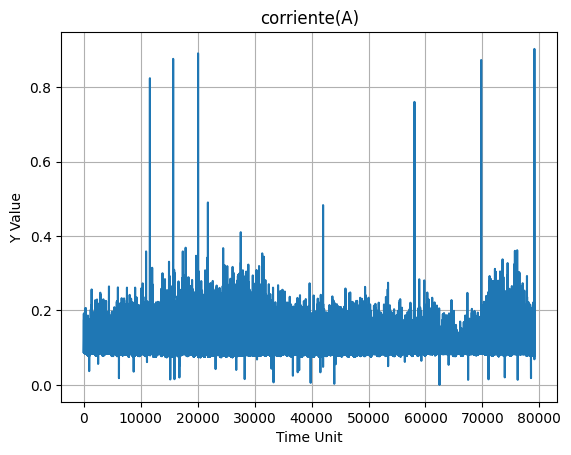

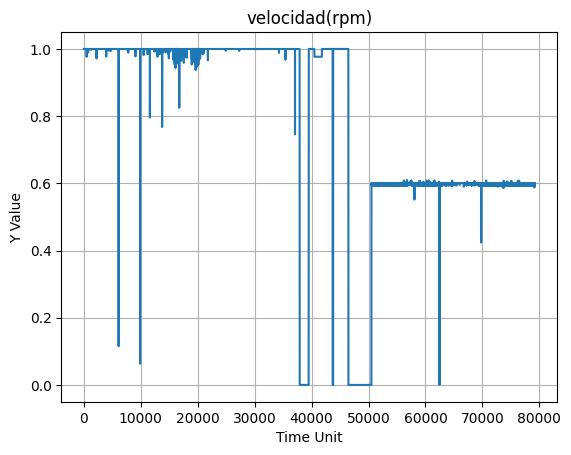

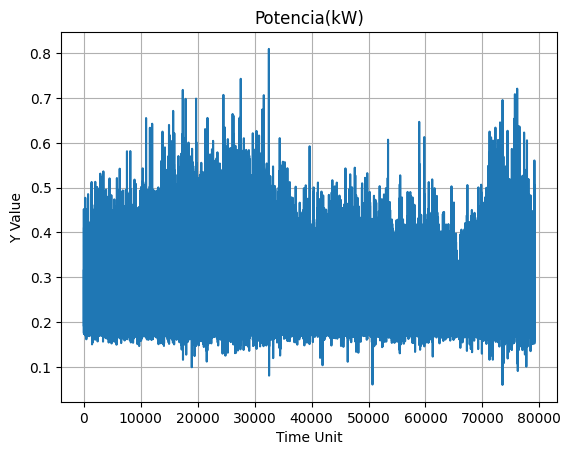

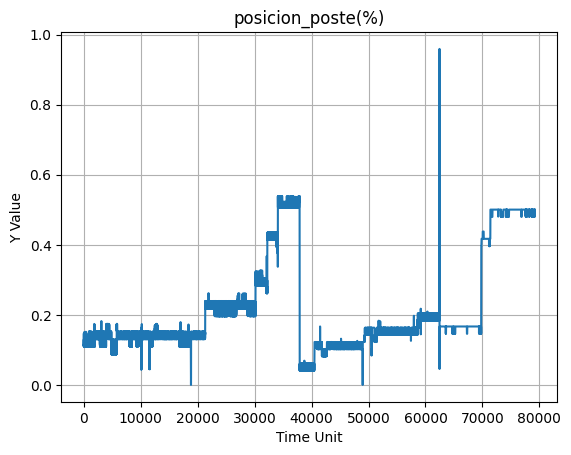

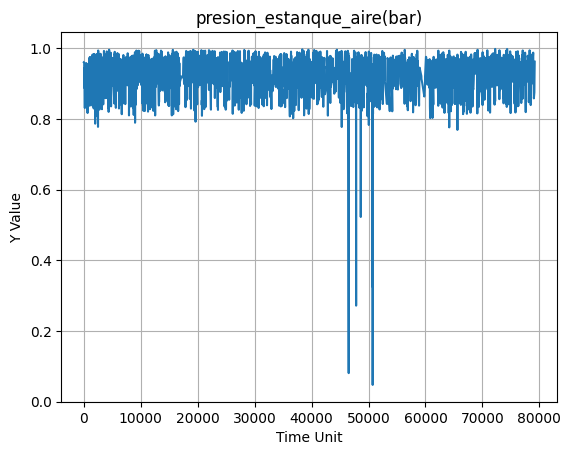

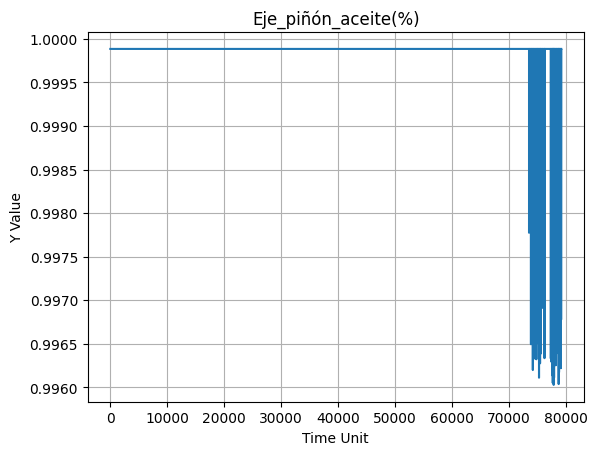

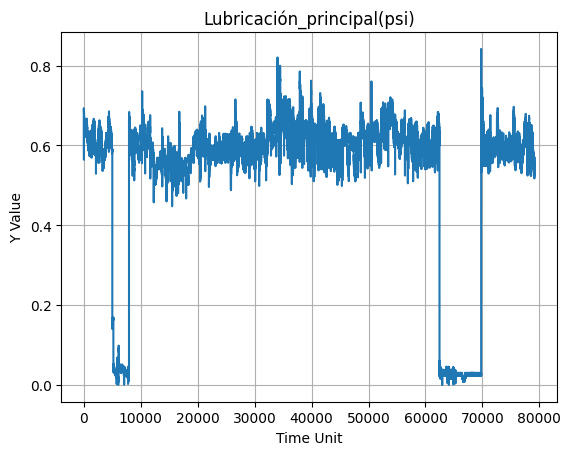

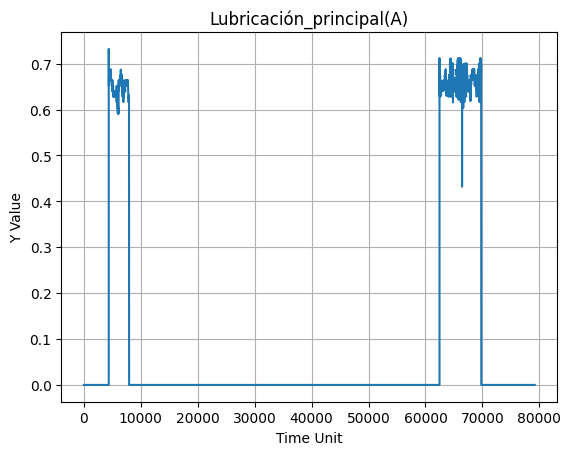

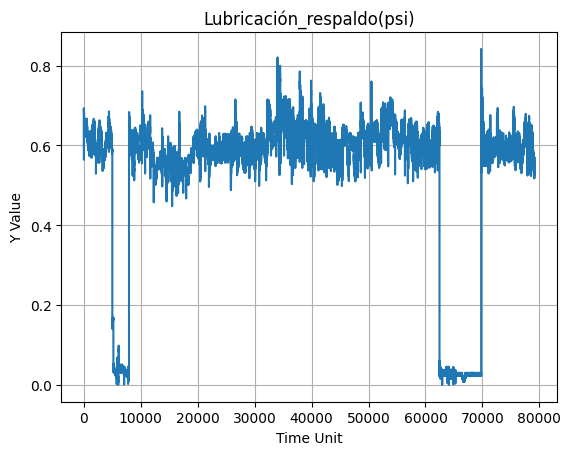

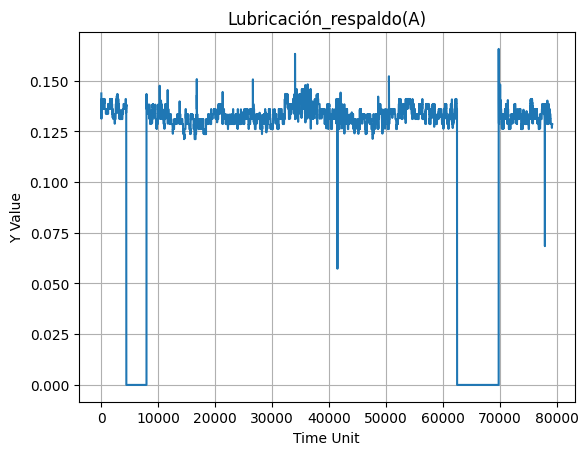

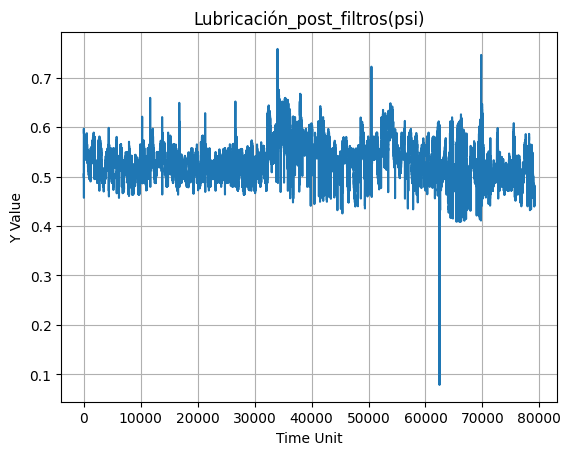

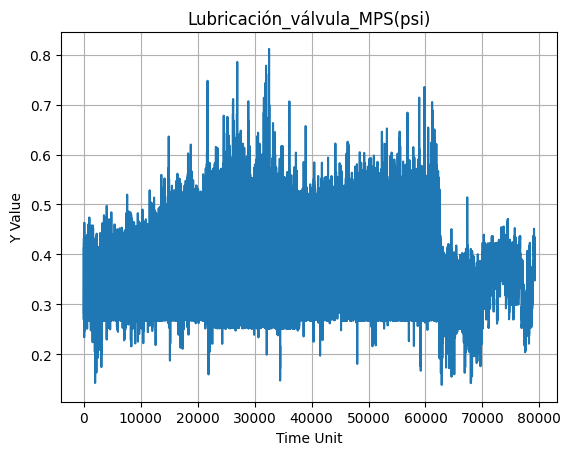

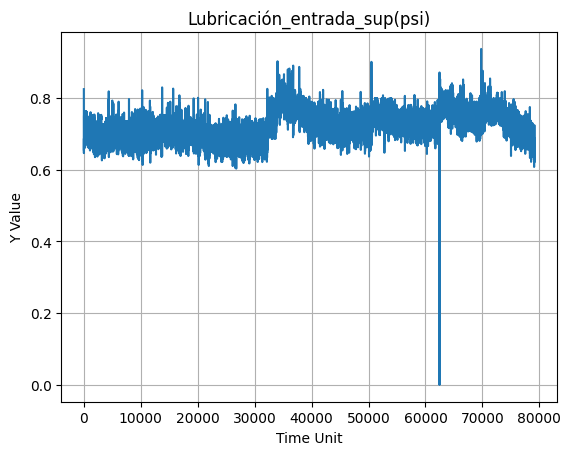

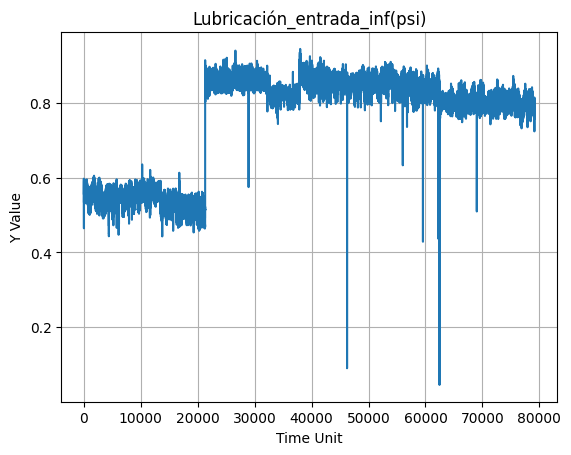

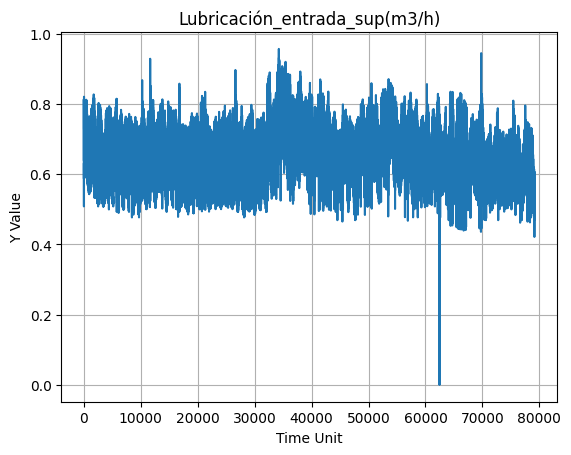

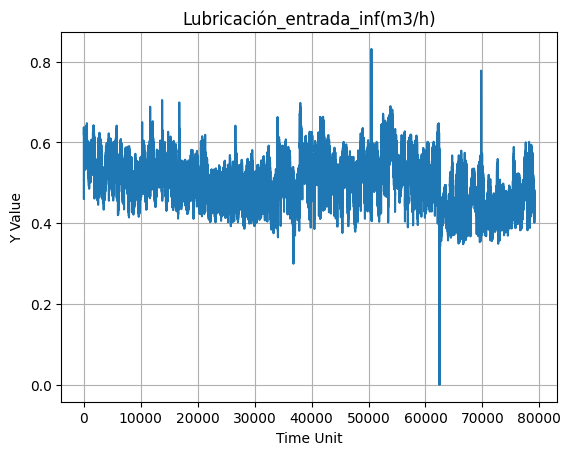

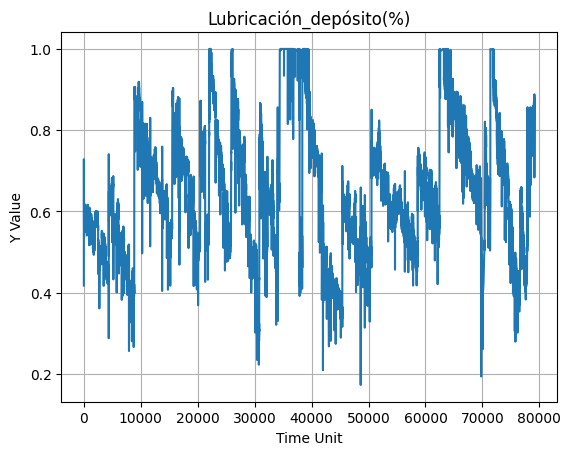

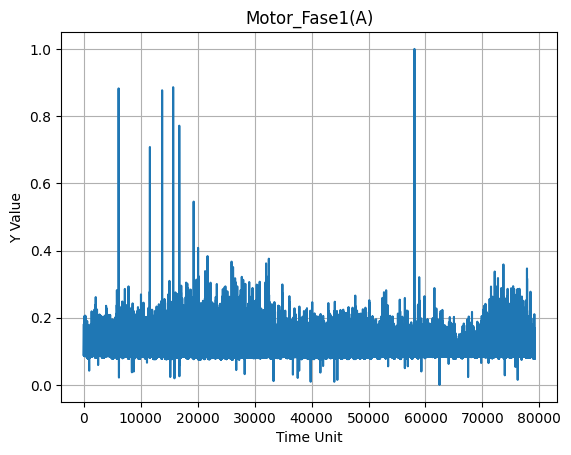

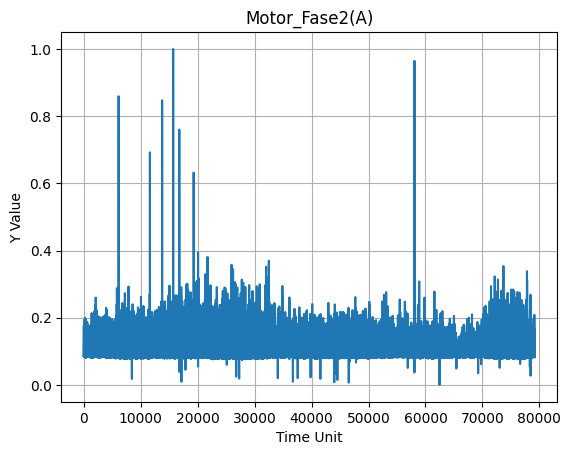

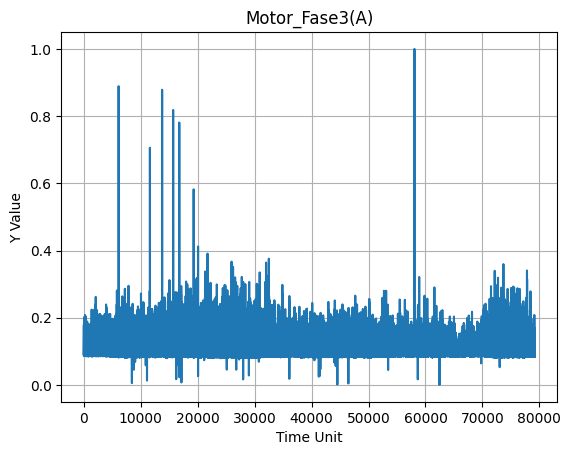

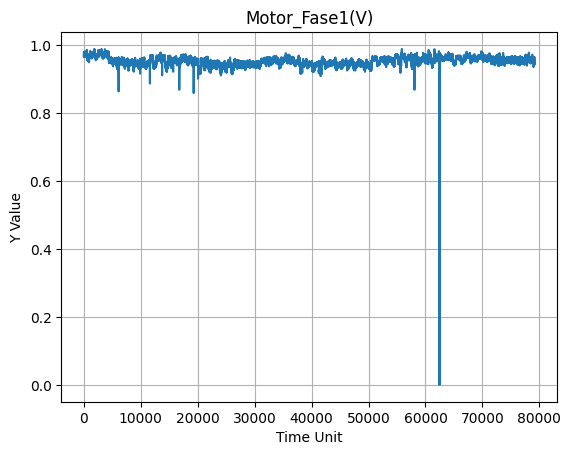

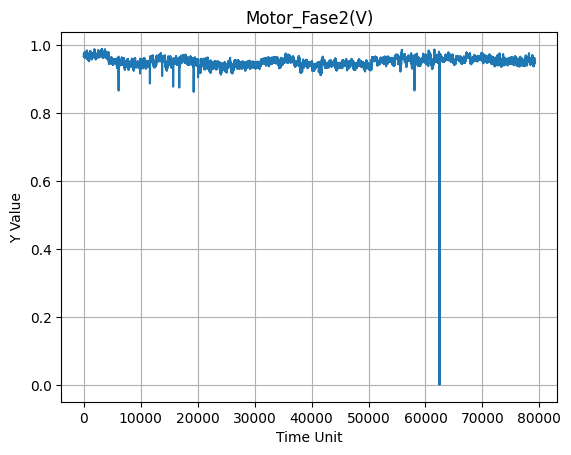

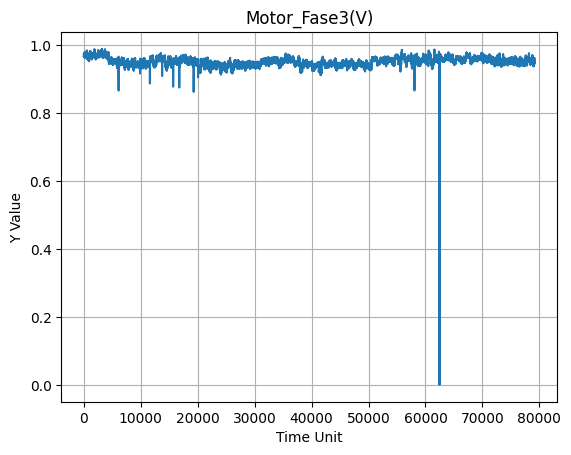

In [15]:
# ============================
# Manipulated variables
# ----------------------------
for idxFeature in preData.manipulatedCr1:
    drawedData = healthyStateData[idxFeature].to_numpy().astype(float)
    matPlot.draw1D(yCoor=drawedData,
                   title=idxFeature)